In [1]:
from sklearn import datasets
import inspect

# Lister les fonctions de chargement de jeux de données dans scikit-learn
dataset_funcs = [
    name
    for name, obj in inspect.getmembers(datasets)
    if callable(obj) and (name.startswith("load_") or name.startswith("fetch_"))
]

# Affichage sous forme de DataFrame Spark pour une visualisation facile dans Fabric
df_datasets = spark.createDataFrame([(name,) for name in sorted(dataset_funcs)], ["dataset_function"])
display(df_datasets)


StatementMeta(, 7436fa7f-fc6e-4179-8782-c73859509a25, 3, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 0f60c560-859f-4f46-939f-d62b74bb100f)

In [2]:
import pandas as pd
from sklearn.datasets import fetch_california_housing

# Charger le dataset California Housing de scikit-learn et le convertir en DataFrame pandas
# as_frame=True permet d'obtenir directement un DataFrame (features + cible)
california = fetch_california_housing(as_frame=True)

# Features (X) en DataFrame
df_features = california.data

# Cible (y) en Series -> on l’ajoute au DataFrame pour avoir un seul dataset pandas complet
df_features["MedHouseVal"] = california.target

# Renommer la colonne cible pour plus de clarté (optionnel)
df_features.rename(columns={"MedHouseVal": "median_house_value"}, inplace=True)

# Afficher un aperçu du DataFrame pandas final
display(df_features.head())

# Si vous souhaitez aussi voir la description du dataset :
print(california.DESCR[:1000])  # on tronque l'affichage pour éviter trop de texte


StatementMeta(, 7436fa7f-fc6e-4179-8782-c73859509a25, 4, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, a4b6d3aa-75c2-498d-bb96-ba7672a6151c)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

StatementMeta(, 7436fa7f-fc6e-4179-8782-c73859509a25, 5, Finished, Available, Finished, False)

2026-11-12 10:52:54 [INFO] setting mlflow tracking uri to sds://api.fabric.microsoft.com/v1/workspaces/717d067d-6487-4392-901a-6a5064f11b86/mlflow, change this environment variable if you want log to other places
🏃 View run modest_bird_btldwxym at: https://api.fabric.microsoft.com/v1/workspaces/717d067d-6487-4392-901a-6a5064f11b86/mlflow/#/experiments/034dfe63-b052-4d88-b5c3-1ec5f90fe270/runs/21c6b758-6678-44b1-b8b7-3c2ae3a3f5cc
🧪 View experiment at: https://api.fabric.microsoft.com/v1/workspaces/717d067d-6487-4392-901a-6a5064f11b86/mlflow/#/experiments/034dfe63-b052-4d88-b5c3-1ec5f90fe270


=== Régression linéaire pour prédire 'median_house_value' ===
R² (test)   : 0.5758
RMSE (test) : 0.7456

Coefficients du modèle (triés) :


SynapseWidget(Synapse.DataFrame, 22c32fbc-e9f4-495a-a3e0-87c509b76f31)

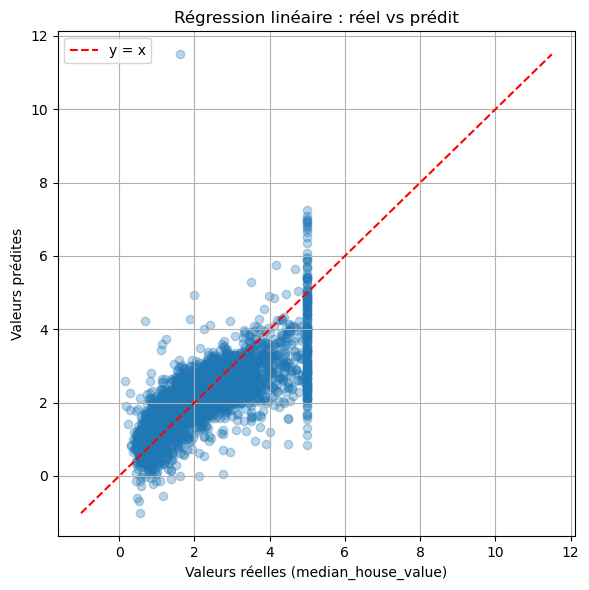

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

import mlflow

# 1. Vérifier que df_features existe (dataset California Housing déjà chargé)
# ==========================================================================
if "df_features" not in globals():
    raise NameError(
        "Le DataFrame 'df_features' n'existe pas. "
        "Exécutez d'abord la cellule qui charge le dataset California Housing."
    )

# Définir explicitement le nom de l'expérience MLflow
mlflow.set_experiment("EXP_california_housing")

# 2. Préparation des données : X (features) et y (cible)
# =====================================================
if "median_house_value" not in df_features.columns:
    raise KeyError(
        "La colonne cible 'median_house_value' est absente de df_features. "
        "Vérifiez la cellule de préparation du dataset."
    )

# X = toutes les colonnes sauf la cible
X = df_features.drop(columns=["median_house_value"])
y = df_features["median_house_value"]

# Gestion simple des valeurs manquantes (suppression de lignes)
mask_not_null = X.notna().all(axis=1) & y.notna()
X = X[mask_not_null]
y = y[mask_not_null]

# 3. Découpage train / test
# =========================
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# 4. Entraînement du modèle de régression linéaire
# ================================================
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Évaluation sur le jeu de test
# ================================
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("=== Régression linéaire pour prédire 'median_house_value' ===")
print(f"R² (test)   : {r2:.4f}")
print(f"RMSE (test) : {rmse:.4f}")

# 6. Affichage des coefficients du modèle
# =======================================
coef_df = pd.DataFrame(
    {
        "feature": X.columns,
        "coefficient": model.coef_
    }
).sort_values("coefficient", ascending=False)

print("\nCoefficients du modèle (triés) :")
display(coef_df)

# 7. Visualisation : valeurs réelles vs prédites
# ==============================================
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.xlabel("Valeurs réelles (median_house_value)")
plt.ylabel("Valeurs prédites")
plt.title("Régression linéaire : réel vs prédit")
# Ligne y = x pour référence
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], "r--", label="y = x")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [4]:
import pandas as pd

# -------------------------------------------------------------------
# 1. Vérifier que le jeu de données California Housing est chargé
#    (df_features doit exister avec la colonne 'median_house_value')
# -------------------------------------------------------------------
if "df_features" not in globals():
    raise NameError(
        "Le DataFrame 'df_features' n'existe pas. "
        "Exécutez d'abord la cellule qui charge le dataset California Housing."
    )

if "median_house_value" not in df_features.columns:
    raise KeyError(
        "La colonne cible 'median_house_value' est absente de df_features. "
        "Vérifiez la cellule de préparation du dataset."
    )

# Colonnes de features du jeu California Housing (sans la cible)
features_cols = [c for c in df_features.columns if c != "median_house_value"]

print("Colonnes de features utilisées :")
print(features_cols)

# -------------------------------------------------------------------
# 2. Créer de nouvelles observations cohérentes avec California Housing
#    (mêmes colonnes, valeurs plausibles)
# -------------------------------------------------------------------
nouvelles_donnees = [
    {
        "MedInc": 4.5,        # revenu médian (10k$)
        "HouseAge": 20.0,     # âge moyen des maisons
        "AveRooms": 5.5,      # nb moyen de pièces
        "AveBedrms": 1.0,     # nb moyen de chambres
        "Population": 800.0,  # population
        "AveOccup": 3.0,      # occupation moyenne
        "Latitude": 34.2,     # latitude en Californie
        "Longitude": -118.3,  # longitude en Californie
    },
    {
        "MedInc": 2.0,
        "HouseAge": 35.0,
        "AveRooms": 4.0,
        "AveBedrms": 1.1,
        "Population": 1000.0,
        "AveOccup": 2.5,
        "Latitude": 36.8,
        "Longitude": -121.9,
    },
    {
        "MedInc": 6.0,
        "HouseAge": 15.0,
        "AveRooms": 6.2,
        "AveBedrms": 1.0,
        "Population": 500.0,
        "AveOccup": 2.8,
        "Latitude": 32.8,
        "Longitude": -117.2,
    },
    {
        "MedInc": 1.5,
        "HouseAge": 45.0,
        "AveRooms": 3.8,
        "AveBedrms": 1.0,
        "Population": 1500.0,
        "AveOccup": 3.5,
        "Latitude": 38.6,
        "Longitude": -121.4,
    },
]

# S'assurer que les colonnes sont dans le même ordre que dans df_features
df_nouvelles_pd = pd.DataFrame(nouvelles_donnees)[features_cols]

print("\nAperçu des nouvelles données pandas :")
display(df_nouvelles_pd)

# -------------------------------------------------------------------
# 3. Conversion en Spark DataFrame et sauvegarde au format Delta
#    dans le Lakehouse par défaut (table gérée Delta)
# -------------------------------------------------------------------
df_nouvelles = spark.createDataFrame(df_nouvelles_pd)

print("\nAperçu des nouvelles données Spark :")
display(df_nouvelles)

nom_table = "nouvelles_donnees_california_features"

(
    df_nouvelles
    .write
    .format("delta")
    .mode("overwrite")  # écrase si la table existe déjà
    .saveAsTable(nom_table)
    # .save("Files/california/nouvelles_donnees_california_features")
)

print(f"Table Delta créée/mise à jour dans le Lakehouse par défaut : {nom_table}")


StatementMeta(, 7436fa7f-fc6e-4179-8782-c73859509a25, 6, Finished, Available, Finished, False)

Colonnes de features utilisées :
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Aperçu des nouvelles données pandas :


SynapseWidget(Synapse.DataFrame, 51a96333-d1b8-4f6f-ba91-10681095a8dc)


Aperçu des nouvelles données Spark :


SynapseWidget(Synapse.DataFrame, 1a3ca3dc-df76-4fdd-a98d-a69e040c8bd2)

Table Delta créée/mise à jour dans le Lakehouse par défaut : nouvelles_donnees_california_features


In [6]:
import mlflow
from synapse.ml.predict import MLFlowTransformer

# Lire la table Delta en utilisant le nom logique de la table dans le Lakehouse par défaut
# (créée dans la cellule précédente avec saveAsTable("nouvelles_donnees_california_features"))
df = spark.read.table("nouvelles_donnees_california_features")

# Configuration du transformeur MLflow (doit correspondre au modèle enregistré dans MLflow)
model = MLFlowTransformer(
    inputCols=[
        "MedInc",
        "HouseAge",
        "AveRooms",
        "AveBedrms",
        "Population",
        "AveOccup",
        "Latitude",
        "Longitude",
    ],
    outputCol="predictions",
    modelName="Housing_reg_lin",
    modelVersion=1,
)

# Appliquer le modèle pour générer les prédictions
pred_df = model.transform(df)

# Sauvegarder les prédictions dans le Lakehouse par défaut en tant que table Delta
# Utilisation de saveAsTable pour rester cohérent avec la création de la table source
pred_table_name = "nouvelles_previsions_california_features"
(
    pred_df.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable(pred_table_name)
)

print(f"Table Delta de prédictions créée/mise à jour : {pred_table_name}")


StatementMeta(, 7436fa7f-fc6e-4179-8782-c73859509a25, 9, Finished, Available, Finished, False)

/opt/spark/python/lib/pyspark.zip/pyspark/sql/pandas/functions.py:761: UserWarning: In Python 3.6+ and Spark 3.0+, it is preferred to specify type hints for pandas UDF instead of specifying pandas UDF type which will be deprecated in the future releases. See SPARK-28264 for more details.


Table Delta de prédictions créée/mise à jour : nouvelles_previsions_california_features


StatementMeta(, 7436fa7f-fc6e-4179-8782-c73859509a25, 10, Finished, Available, Finished, False)

In [7]:
df_predict = spark.sql("SELECT * FROM LK_data_science.dbo.nouvelles_previsions_california_features LIMIT 1000")
display(df_predict)

StatementMeta(, 7436fa7f-fc6e-4179-8782-c73859509a25, 11, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 2e71b43f-ae53-49d3-a0e0-418af4828fd5)

In [ ]:
import subprocess

# Récupérer un jeton d'accès Fabric via Azure CLI
# Commande équivalente à :
# az account get-access-token --resource https://api.fabric.microsoft.com --query accessToken -o tsv
result = subprocess.run(
    [
        "az",
        "account",
        "get-access-token",
        "--resource",
        "https://api.fabric.microsoft.com",
        "--query",
        "accessToken",
        "-o",
        "tsv",
    ],
    check=True,
    capture_output=True,
    text=True,
)

fabric_token = result.stdout.strip()

if not fabric_token:
    raise RuntimeError("Impossible de récupérer le token via Azure CLI.")

# Par sécurité, on n'affiche qu'un extrait du token
print("Token Fabric récupéré (début) :", fabric_token[:20] + "...")


StatementMeta(, , -1, SessionError, , SessionError, True)

InvalidHttpRequest: [TooManyRequestsForCapacity] [TooManyRequestsForCapacity] HTTP Response code 430: This Spark job can't be run because you've hit spark overall capacity compute limit. To proceed, cancel an active Spark job through the Monitoring hub, choose a larger capacity SKU, or try again later. For more visibility and control, go to Workspace settings → Job management (Job Concurrency & Queue Monitoring) to review running and queued Spark jobs, understand capacity contention, and take action as needed. [Learn more at 'https://go.microsoft.com/fwlink/?linkid=2356970&clcid=0x409']. HTTP status code: 430.

In [9]:
import os
import json
import requests

# Récupérer le token Fabric depuis la variable d'environnement
fabric_token = "eyJ0eXAiOiJKV1QiLCJhbGciOiJSUzI1NiIsIng1dCI6InhIOURKSDNOMDg2QWdzOEpMNklRemVRaDFwOCIsImtpZCI6InhIOURKSDNOMDg2QWdzOEpMNklRemVRaDFwOCJ9.eyJhdWQiOiJodHRwczovL2FwaS5mYWJyaWMubWljcm9zb2Z0LmNvbSIsImlzcyI6Imh0dHBzOi8vc3RzLndpbmRvd3MubmV0LzY0OTQ0NjBlLTg2MDAtNGVkYy04NTBmLTUyOGU4ZmFhZDI5MC8iLCJpYXQiOjE3OTQ0ODE2MjYsIm5iZiI6MTc5NDQ4MTYyNiwiZXhwIjoxNzk0NDg1NzYxLCJhY2N0IjowLCJhY3IiOiIxIiwiYWlvIjoiQWRRQUsvOGVBQUFBcDdHTDJ6aEpLdHVyT1pidmc0SWEyYm5zWTZEdlU4S1g0L0RuTmNZQUc0WHYxaEhJR0F0ZU9velIrSXJ0TUwvVGlRVjlmSkptM0xvTCtDRndRVU53dXcrK1R6WDVXRFlqYUcveFhZMzdyY1hvL244TFByQStoOFJqdTZ2aTRBTmRaTXRUZ0pZc095d3VtQmhHck1mbndrVXZZc0trK1ZhSy94NCtnQWZYdmJJYldQVWErczlpSExnWlhyMlF4RFdCalNpYVVPU2hEaGo0aXJMVWFjSGx3bHpOa3Jpeldzeng2cXBObkd5VlBuWmdaQ2ZPYWtOMlhUNzdoTS81TnhNVk80ajBKWkIrcHZJN0lQYjl4azlYK3c9PSIsImFtciI6WyJwd2QiLCJyc2EiLCJtZmEiXSwiYXBwaWQiOiIwNGIwNzc5NS04ZGRiLTQ2MWEtYmJlZS0wMmY5ZTFiZjdiNDYiLCJhcHBpZGFjciI6IjAiLCJkZXZpY2VpZCI6IjBhNWQ0MWNhLWI5MWItNDQ4Yi04MzVhLWI4ZmY5ZTRkZWRjYSIsImZhbWlseV9uYW1lIjoiUEVUT04iLCJnaXZlbl9uYW1lIjoiUGF1bCIsImlkdHlwIjoidXNlciIsImlwYWRkciI6IjEwOS4yMjIuMTM5LjgzIiwibmFtZSI6IlBhdWwgUEVUT04iLCJvaWQiOiJmNDUyYzQxNi02M2M1LTQ5N2ItYjNiMi1mNGMxYzkyNzQ4ZmEiLCJvbnByZW1fc2lkIjoiUy0xLTUtMjEtODY5NjEwNTQyLTI3NDY1NzE4MzktMzc5MzQ4OTExLTE5MTkzIiwicHVpZCI6IjEwMDMyMDA0NUQwMTYwOTUiLCJwd2RfdXJsIjoiaHR0cHM6Ly9nby5taWNyb3NvZnQuY29tL2Z3bGluay8_bGlua2lkPTIyMjQxOTgiLCJyaCI6IjEuQVI4QURrYVVaQUNHM0U2RkQxS09qNnJTa0FrQUFBQUFBQUFBd0FBQUFBQUFBQUNGQUxNZkFBLiIsInNjcCI6InVzZXJfaW1wZXJzb25hdGlvbiIsInNpZCI6IjAwN2E2ODA5LTE1OWItM2Y5Zi1lMWZlLTVhMTJmMTEzOWQzNyIsInNpZ25pbl9zdGF0ZSI6WyJkdmNfbW5nZCIsImR2Y19jbXAiLCJkdmNfZG1qZCJdLCJzdWIiOiJOdThaN2g0WW56OVJ4b25paEd2RERfTVdyTlUwNnRDMFp4Y3JRTVU0Slk4IiwidGlkIjoiNjQ5NDQ2MGUtODYwMC00ZWRjLTg1MGYtNTI4ZThmYWFkMjkwIiwidW5pcXVlX25hbWUiOiJwcGV0b25AZXhwZXJ0aW1lLmNvbSIsInVwbiI6InBwZXRvbkBleHBlcnRpbWUuY29tIiwidXRpIjoicm1kT3d0VE9xRWFEVUtrYjZyd0hBQSIsInZlciI6IjEuMCIsIndpZHMiOlsiYjc5ZmJmNGQtM2VmOS00Njg5LTgxNDMtNzZiMTk0ZTg1NTA5Il0sInhtc19hY3RfZmN0IjoiMyA1IiwieG1zX2F1ZF9ndWlkIjoiMDAwMDAwMDktMDAwMC0wMDAwLWMwMDAtMDAwMDAwMDAwMDAwIiwieG1zX2NjIjpbIkNQMSJdLCJ4bXNfZnRkIjoiOWJNc1Y3Z2s2Uk8xbjFqYzlocHZqUjlrYXhUbW5OUEZycE5IMFFIZW5DNEJabkpoYm1ObFl5MWtjMjF6IiwieG1zX2lkcmVsIjoiMSA0IiwieG1zX3N1Yl9mY3QiOiIxOCAzIn0.fWpi4C78-QWubRQOd9L3_yKL5wMPaz7m034e1kF6dfqhOLNOAR-unDEkEoANG-J6Q1JhYv-b3CliaV6-1Gf6ZNZxc9DIRZNdKub34nfrHpsASPgQn-TLTAoz_oh11X6orLx1kjno0U1DBrobD9X_u4JJfGQ0_luOqijF7BomIdaoSCm2TIB14R7L5HljhRQJlG2GF1i7FOf553wupb5zFoeb36a2HknRYRFBwL7yU_CsPKGiySIIWeT0hzblIPOc1jdtzXpRtDeXXslUxK1DzgNbKAS4HmQ70PlB7nRy5UjWvXIQ5j7aaG858qe7RsEJThv9dyefnA3vrAMhdXsgUQ"
if not fabric_token:
    raise RuntimeError("La variable d'environnement 'FABRIC_TOKEN' n'est pas définie.")

# URL de scoring (identique à celle utilisée dans la commande curl)
url = "https://api.fabric.microsoft.com/v1/workspaces/717d067d-6487-4392-901a-6a5064f11b86/mlmodels/b072e459-cc42-4f4a-8472-e82b5eeba265/endpoint/versions/1/score"

# Exemple de payload adapté au dataset California Housing :
# - mêmes features que dans le modèle : MedInc, HouseAge, AveRooms, AveBedrms,
#   Population, AveOccup, Latitude, Longitude
# - structure de type "input_data" avec "columns" et "data" (schéma classique MLflow/pyfunc)
payload = {
    "input_data": {
        "columns": [
            "MedInc",
            "HouseAge",
            "AveRooms",
            "AveBedrms",
            "Population",
            "AveOccup",
            "Latitude",
            "Longitude",
        ],
        "data": [
            [4.5, 20.0, 5.5, 1.0, 800.0, 3.0, 34.2, -118.3],
            [2.0, 35.0, 4.0, 1.1, 1000.0, 2.5, 36.8, -121.9],
            [6.0, 15.0, 6.2, 1.0, 500.0, 2.8, 32.8, -117.2],
            [1.5, 45.0, 3.8, 1.0, 1500.0, 3.5, 38.6, -121.4],
        ],
    }
}

headers = {
    "Content-Type": "application/json",
}

# Appel HTTP avec authentification basique (token:FABRIC_TOKEN)
response = requests.post(
    url,
    headers=headers,
    auth=("token", fabric_token),
    json=payload,
    timeout=30,
)

print("Statut:", response.status_code)
try:
    print("Réponse JSON:", response.json())
except ValueError:
    print("Réponse brute:", response.text)


StatementMeta(, 7436fa7f-fc6e-4179-8782-c73859509a25, 13, Finished, Available, Finished, False)

Statut: 401
Réponse JSON: {'requestId': '3e9daf47-9409-462c-b0f1-64ce27b6f0bd', 'errorCode': 'RequestFailed', 'message': 'Unable to process the request', 'isRetriable': False}
